# Cognifyz Machine Learning Internship
## Task 1: Predict Restaurant Ratings

---

### **Project Overview & Objectives**
In the competitive restaurant and hospitality industry, customer ratings serve as a critical proxy for reputation, customer satisfaction, and business viability. The objective of this project is to build, evaluate, and interpret machine learning regression models to predict the **`Aggregate rating`** (a continuous score typically ranging between 0.0 and 5.0) of restaurants based on their operational, geographical, and commercial attributes.

### **Workflow Roadmap**
1. **Data Ingestion & Integrity Audit:** Load `Dataset .csv`, inspect shape, data types, missing values, and handle incomplete records (dropping the 9 rows missing `Cuisines`).
2. **Feature Selection & Leakage Prevention:** Remove non-predictive identifier columns and target leakage variables (`Rating color`, `Rating text`) to ensure fair, unbiased generalization.
3. **Feature Encoding & Engineering:** Map binary variables (`Yes`/`No`) to numerical integers (`1`/`0`), and apply **Frequency Encoding** to high-cardinality categorical features (`City`, `Cuisines`, `Currency`).
4. **Data Partitioning:** Split features and target into an 80% training set and a 20% test set with a fixed random seed (`random_state=42`) for reproducibility.
5. **Model Development:** Train three regression algorithms representing distinct paradigms:
   - **Linear Regression** (Parametric baseline)
   - **Decision Tree Regressor** (Non-linear single tree)
   - **Random Forest Regressor** (Ensemble bagging of decision trees)
6. **Model Evaluation & Comparative Analysis:** Evaluate models on unseen test data using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and $R^2$ Score, followed by a comparative performance summary table and diagnostic visualizations.
7. **Feature Importance Interpretation & Key Findings:** Extract and visualize the top 10 most influential features driving restaurant ratings from the best-performing model, culminating in an executive summary and business recommendations.


### **Environment Setup: Library Imports & Configuration**
We begin by importing standard scientific computing, data manipulation, machine learning, and visualization libraries. We also configure aesthetic parameters for Matplotlib and Seaborn to produce publication-grade charts.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules for modeling and evaluation
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Configure visualization aesthetics
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_theme(style='whitegrid', palette='muted')

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


---
## **Step 1: Load Data, Inspect Structure & Handle Missing Values**

### **Context & Strategy**
The dataset contains restaurant-level attributes across multiple countries, including geographical coordinates, price tiers, dining and delivery options, and user feedback metrics.

In this step, we:
1. Load `Dataset .csv` into a Pandas DataFrame.
2. Inspect the dataset's dimensions, data types, and null value counts across all columns.
3. Handle missing values: The dataset contains exactly 9 missing entries in the `Cuisines` column out of 9,551 total records (< 0.1%). Dropping these 9 rows is the most robust strategy as imputing complex cuisine combinations could introduce artificial noise.


In [2]:
# 1. Load the dataset
df = pd.read_csv('Dataset .csv')

print(f"Initial Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns\n")

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Inspect data types and non-null counts
print("\nDataset Info:")
df.info()

# Inspect missing values count per column
print("\nMissing Values Summary:")
missing_vals = df.isnull().sum()
missing_summary = missing_vals[missing_vals > 0]
if len(missing_summary) > 0:
    print(missing_summary)
else:
    print("No missing values found.")

# Drop rows with missing 'Cuisines' (9 rows)
initial_rows = len(df)
df.dropna(subset=['Cuisines'], inplace=True)
df.reset_index(drop=True, inplace=True)
dropped_rows = initial_rows - len(df)

print(f"\nSuccessfully dropped {dropped_rows} rows with missing 'Cuisines'.")
print(f"Cleaned Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns.")
assert df['Cuisines'].isnull().sum() == 0, "Missing values still exist in Cuisines!"


Initial Dataset Shape: 9,551 rows and 21 columns

First 5 rows of the dataset:


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order m

---
## **Step 2: Drop Non-Predictive and Target Leakage Columns**

### **Rationale for Feature Exclusion**
A critical phase in building generalized machine learning models is ensuring that input features do not introduce **data leakage** or **arbitrary noise**:

1. **Non-Predictive Text Identifiers (`Restaurant ID`, `Restaurant Name`, `Address`, `Locality Verbose`, `Locality`):**
   - `Restaurant ID` and `Restaurant Name` are arbitrary identifiers that provide zero predictive relationship to restaurant quality across new businesses.
   - `Address`, `Locality Verbose`, and `Locality` are free-form, high-cardinality location text strings (over 1,200 unique localities). Hyper-local geographic location is already accurately captured by numerical spatial coordinates (`Longitude`, `Latitude`) and `City`. Keeping these textual identifiers would lead to severe overfitting and curse of dimensionality.
2. **Target Leakage (`Rating color`, `Rating text`):**
   - In the Zomato schema, `Rating text` (e.g., *"Excellent"*, *"Very Good"*, *"Poor"*) and `Rating color` (e.g., *"Dark Green"*, *"Green"*, *"Orange"*) are deterministic categorizations derived directly from `Aggregate rating` (the target variable). For example, any rating between 4.5 and 5.0 is mapped to *"Dark Green"* / *"Excellent"*.
   - Including them as predictive features would result in **target leakage**, artificially inflating model accuracy during testing while failing completely when predicting ratings for unrated or newly listed restaurants in production.


In [3]:
# Define columns to drop
drop_cols = [
    'Restaurant ID',       # Unique identifier (non-predictive)
    'Restaurant Name',     # Entity name (non-predictive)
    'Address',             # Free-form textual address (high cardinality)
    'Locality',            # Granular neighborhood text (redundant with coordinates & City)
    'Locality Verbose',    # Extended neighborhood text (redundant)
    'Rating color',        # Target leakage (binned target)
    'Rating text'          # Target leakage (binned target)
]

print("Columns before dropping:", df.columns.tolist())
df.drop(columns=drop_cols, inplace=True)
print(f"\nDropped {len(drop_cols)} columns: {drop_cols}")
print(f"Remaining Columns ({df.shape[1]} total):\n{df.columns.tolist()}\n")
print(f"Dataset Shape after dropping non-predictive/leakage columns: {df.shape}")
display(df.head(3))


Columns before dropping: ['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']

Dropped 7 columns: ['Restaurant ID', 'Restaurant Name', 'Address', 'Locality', 'Locality Verbose', 'Rating color', 'Rating text']
Remaining Columns (14 total):
['Country Code', 'City', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Votes']

Dataset Shape after dropping non-predictive/leakage columns: (9542, 14)


,Country Code,City,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Votes
0,162,Makati City,121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,314
1,162,Makati City,121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,591
2,162,Mandaluyong City,121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,270


---
## **Step 3: Feature Encoding (Binary Variables & High-Cardinality Categoricals)**

### **Encoding Strategy**
Machine learning regression algorithms require numerical inputs. We handle categorical features using targeted encoding methods:

1. **Binary Yes/No Encoding:**
   - Columns: `Has Table booking`, `Has Online delivery`, `Is delivering now`, `Switch to order menu`.
   - We convert these using a simple binary mapping: `{'Yes': 1, 'No': 0}`.
2. **High-Cardinality Categorical Encoding (`City`, `Cuisines`, `Currency`):**
   - `Cuisines` contains **1,825 unique combinations**, `City` contains **141 unique cities**, and `Currency` contains **12 distinct currencies**.
   - **Why Frequency Encoding over One-Hot Encoding?**
     - One-Hot Encoding would expand the dataset by over 1,900 sparse binary columns. This would trigger the *curse of dimensionality*, dramatically increase memory consumption, slow down tree ensemble splits, and cause linear models to overfit.
     - **Frequency Encoding** (also known as Count / Prevalence Encoding) replaces each categorical value with its relative normalized frequency (proportion of occurrences in the dataset). This preserves category prominence and popularity rank in a single dense column without increasing the feature space dimensionality.


In [4]:
# 1. Convert binary Yes/No columns to 1/0
binary_cols = ['Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu']

print("Binary Column Value Counts (Before Mapping):")
for col in binary_cols:
    print(f"  {col}: {dict(df[col].value_counts())}")

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0}).fillna(0).astype(int)

print("\nBinary Column Value Counts (After Mapping):")
for col in binary_cols:
    print(f"  {col}: {dict(df[col].value_counts())}")

# 2. Apply Frequency Encoding to high-cardinality categorical features
categorical_cols = ['City', 'Cuisines', 'Currency']

print("\nUnique value counts before Frequency Encoding:")
for col in categorical_cols:
    print(f"  {col}: {df[col].nunique()} unique categories")

# Apply normalized frequency encoding
for col in categorical_cols:
    freq_map = df[col].value_counts(normalize=True)
    df[col] = df[col].map(freq_map)

print("\nPreview of encoded dataset:")
display(df.head(5))

# Verify all columns are now numerical
print("\nData types of all remaining features:")
print(df.dtypes)
assert df.select_dtypes(include=['object']).shape[1] == 0, "Categorical/object columns still remain!"


Binary Column Value Counts (Before Mapping):
  Has Table booking: {'No': np.int64(8384), 'Yes': np.int64(1158)}
  Has Online delivery: {'No': np.int64(7091), 'Yes': np.int64(2451)}
  Is delivering now: {'No': np.int64(9508), 'Yes': np.int64(34)}
  Switch to order menu: {'No': np.int64(9542)}

Binary Column Value Counts (After Mapping):
  Has Table booking: {0: np.int64(8384), 1: np.int64(1158)}
  Has Online delivery: {0: np.int64(7091), 1: np.int64(2451)}
  Is delivering now: {0: np.int64(9508), 1: np.int64(34)}
  Switch to order menu: {0: np.int64(9542)}

Unique value counts before Frequency Encoding:
  City: 140 unique categories
  Cuisines: 1825 unique categories
  Currency: 12 unique categories

Preview of encoded dataset:


,Country Code,City,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Votes
0,162,0.000210,121.027535,14.565443,0.000105,1100,0.002306,1,0,0,0,3,4.8,314
1,162,0.000210,121.014101,14.553708,0.001782,1200,0.002306,1,0,0,0,3,4.5,591
2,162,0.000419,121.056831,14.581404,0.000105,4000,0.002306,1,0,0,0,4,4.4,270
3,162,0.000419,121.056475,14.585318,0.001886,1500,0.002306,0,0,0,0,4,4.9,365
4,162,0.000419,121.057508,14.584450,0.000314,1500,0.002306,1,0,0,0,4,4.8,229



Data types of all remaining features:
Country Code              int64
City                    float64
Longitude               float64
Latitude                float64
Cuisines                float64
Average Cost for two      int64
Currency                float64
Has Table booking         int64
Has Online delivery       int64
Is delivering now         int64
Switch to order menu      int64
Price range               int64
Aggregate rating        float64
Votes                     int64
dtype: object


---
## **Step 4: Split Data into Training (80%) and Testing (20%) Sets**

### **Methodology**
We partition the dataset into:
- **Feature Matrix ($X$):** All independent variables predicting restaurant ratings.
- **Target Vector ($y$):** The continuous variable `Aggregate rating`.

We use `train_test_split` with an 80/20 train-test ratio and set `random_state=42` to guarantee exact reproducibility across all model training and testing runs.


In [5]:
# Define features (X) and target (y)
X = df.drop(columns=['Aggregate rating'])
y = df['Aggregate rating']

# Perform 80% Train, 20% Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("=" * 50)
print(f"Total Samples     : {len(df):,}")
print(f"Training Samples  : {X_train.shape[0]:,} (80%)")
print(f"Testing Samples   : {X_test.shape[0]:,} (20%)")
print(f"Number of Features: {X_train.shape[1]}")
print("=" * 50)
print(f"Feature names     : {list(X.columns)}")
print(f"Target variable   : Aggregate rating (Min: {y.min()}, Max: {y.max()}, Mean: {y.mean():.2f})")


Total Samples     : 9,542
Training Samples  : 7,633 (80%)
Testing Samples   : 1,909 (20%)
Number of Features: 13
Feature names     : ['Country Code', 'City', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Votes']
Target variable   : Aggregate rating (Min: 0.0, Max: 4.9, Mean: 2.67)


---
## **Step 5: Model Selection and Training**

### **Algorithm Selection Rationale**
To identify the most accurate and reliable architecture for rating prediction, we train and compare three distinct regression models:

1. **Linear Regression (Baseline Parametric Model):**
   - Assumes a linear additive relationship between the predictors and the target rating: $\hat{y} = \beta_0 + \sum \beta_i x_i$.
   - Provides an interpretable benchmark to assess whether linear combinations can adequately explain restaurant ratings.
2. **Decision Tree Regressor (Non-Parametric Tree Model):**
   - Partitions feature space using orthogonal recursive binary splits based on variance reduction.
   - Capable of modeling non-linear interactions and threshold steps (e.g. unrated restaurants with zero votes).
3. **Random Forest Regressor (Ensemble Bagging Model):**
   - Constructs an ensemble of 100 decorrelated decision trees using bootstrap aggregating (bagging) and random feature subspace sampling.
   - Substantially reduces variance, mitigates single-tree overfitting, and yields robust generalization on tabular data.


In [6]:
import time

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

trained_models = {}
training_times = {}

print("Training models...")
for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start_time
    trained_models[name] = model
    training_times[name] = elapsed
    print(f"  ✓ {name:20s} trained in {elapsed:.3f} seconds.")

print("\nAll models trained successfully!")


Training models...
  ✓ Linear Regression    trained in 0.039 seconds.
  ✓ Decision Tree        trained in 0.027 seconds.
  ✓ Random Forest        trained in 0.277 seconds.

All models trained successfully!


---
## **Step 6: Model Evaluation & Performance Comparison**

### **Evaluation Metrics**
We evaluate all three models on the unseen **test set (20%)** using standard regression metrics:
1. **Mean Squared Error (MSE):** Measures the average squared difference between actual ratings and predictions:
   $$\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
2. **Root Mean Squared Error (RMSE):** Represents the standard deviation of prediction errors in the original rating scale (0 to 5):
   $$\text{RMSE} = \sqrt{\text{MSE}}$$
3. **$R^2$ Score (Coefficient of Determination):** Measures the proportion of variance in `Aggregate rating` explained by the model:
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$


             RESTAURANT RATING REGRESSION PERFORMANCE
            Model      MSE     RMSE  R-squared (R2)  Training Time (s)
    Random Forest 0.094811 0.307914        0.958598           0.277334
    Decision Tree 0.186930 0.432354        0.918372           0.026581
Linear Regression 1.497941 1.223904        0.345887           0.039042


,Model,MSE,RMSE,R-squared (R2),Training Time (s)
0,Random Forest,0.0948,0.3079,0.9586,0.277
1,Decision Tree,0.1869,0.4324,0.9184,0.027
2,Linear Regression,1.4979,1.2239,0.3459,0.039


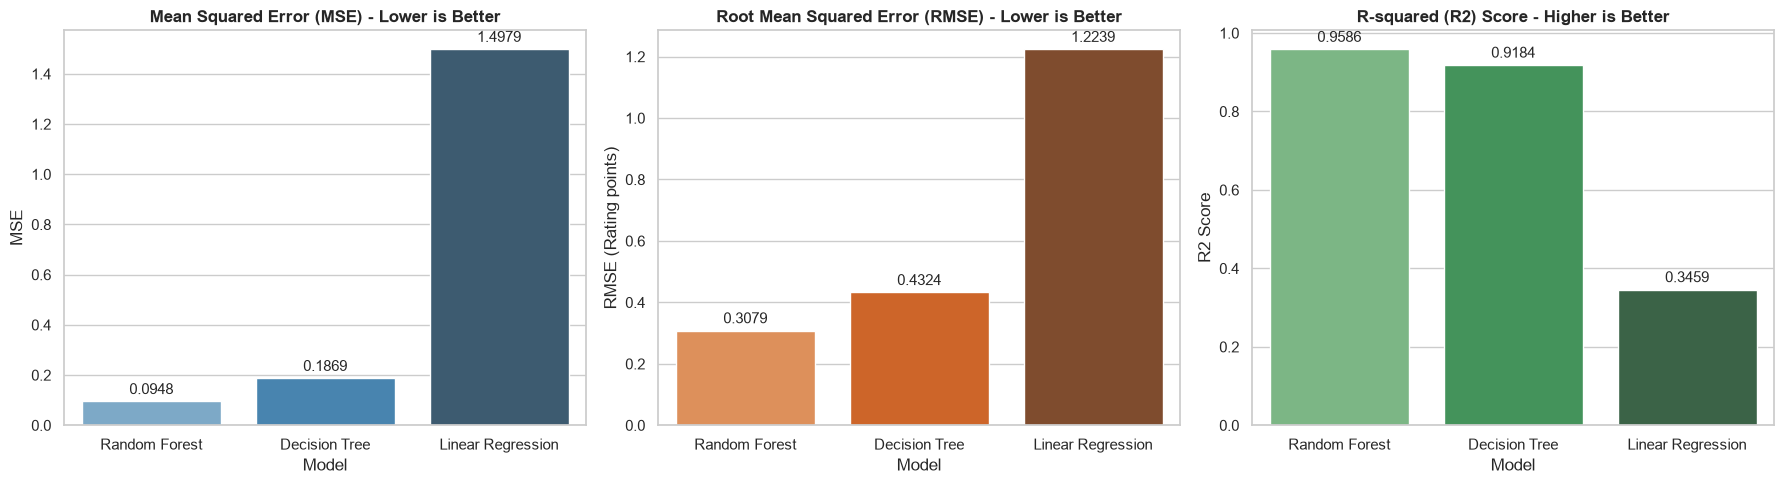

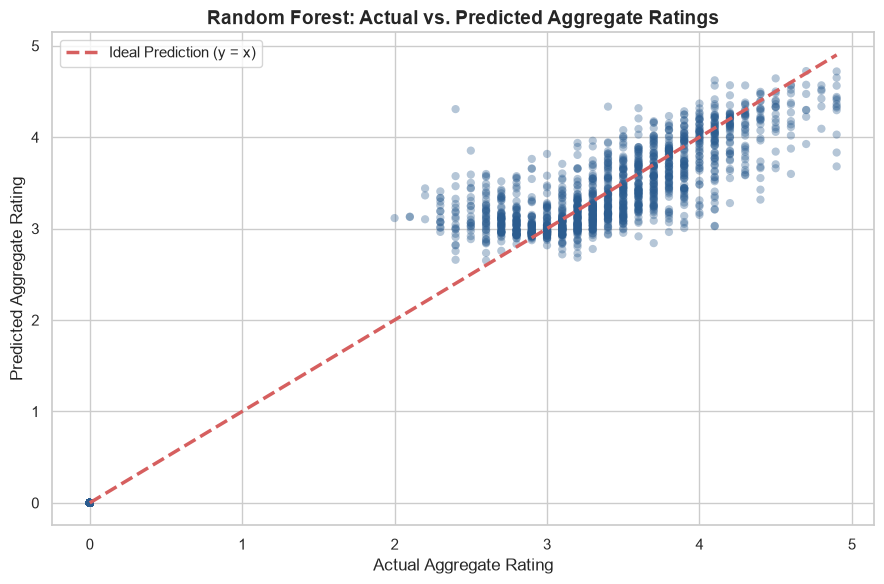

In [7]:
# Generate predictions and evaluate metrics on test set
results = []
predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'MSE': mse,
        'RMSE': rmse,
        'R-squared (R2)': r2,
        'Training Time (s)': training_times[name]
    })

# Construct performance comparison DataFrame
results_df = pd.DataFrame(results).sort_values(by='R-squared (R2)', ascending=False).reset_index(drop=True)

print("=" * 70)
print("             RESTAURANT RATING REGRESSION PERFORMANCE")
print("=" * 70)
print(results_df.to_string(index=False))
print("=" * 70)
display(results_df.style.format({
    'MSE': '{:.4f}',
    'RMSE': '{:.4f}',
    'R-squared (R2)': '{:.4f}',
    'Training Time (s)': '{:.3f}'
}).highlight_min(subset=['MSE', 'RMSE'], color='lightgreen')
  .highlight_max(subset=['R-squared (R2)'], color='lightgreen'))

# Visual Comparison of Models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot MSE
sns.barplot(data=results_df, x='Model', y='MSE', ax=axes[0], palette='Blues_d')
axes[0].set_title('Mean Squared Error (MSE) - Lower is Better', fontweight='bold')
axes[0].set_ylabel('MSE')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

# Plot RMSE
sns.barplot(data=results_df, x='Model', y='RMSE', ax=axes[1], palette='Oranges_d')
axes[1].set_title('Root Mean Squared Error (RMSE) - Lower is Better', fontweight='bold')
axes[1].set_ylabel('RMSE (Rating points)')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

# Plot R-squared
sns.barplot(data=results_df, x='Model', y='R-squared (R2)', ax=axes[2], palette='Greens_d')
axes[2].set_title('R-squared (R2) Score - Higher is Better', fontweight='bold')
axes[2].set_ylabel('R2 Score')
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# Actual vs Predicted Ratings for the Best Model (Random Forest)
plt.figure(figsize=(9, 6))
plt.scatter(y_test, predictions['Random Forest'], alpha=0.35, color='#2b5c8f', edgecolors='none', s=35)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2.5, label='Ideal Prediction (y = x)')
plt.title('Random Forest: Actual vs. Predicted Aggregate Ratings', fontweight='bold', fontsize=14)
plt.xlabel('Actual Aggregate Rating', fontsize=12)
plt.ylabel('Predicted Aggregate Rating', fontsize=12)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


---
## **Step 7: Top 10 Influential Features (Random Forest) & Visual Analysis**

### **Feature Importance Methodology**
In Random Forest regression, feature importance is calculated using **Mean Decrease in Impurity (MDI)**. Every time a decision tree splits on a given feature, the variance of the target variable in the child nodes decreases. MDI aggregates this variance reduction across all 100 trees in the ensemble, normalized so that the total importance across all features sums to 1.0 (100%).

Extracting these importances enables us to understand the underlying behavioral and operational drivers of restaurant ratings.


       TOP 10 MOST INFLUENTIAL FEATURES (RANDOM FOREST)
             Feature  Importance  Importance (%)
               Votes    0.944436       94.443619
                City    0.016533        1.653282
           Longitude    0.011258        1.125787
            Latitude    0.009811        0.981128
            Cuisines    0.007218        0.721834
Average Cost for two    0.006530        0.652986
            Currency    0.001369        0.136918
 Has Online delivery    0.001183        0.118310
         Price range    0.000935        0.093540
   Has Table booking    0.000497        0.049734


,Feature,Importance,Importance (%)
0,Votes,0.94444,94.44%
1,City,0.01653,1.65%
2,Longitude,0.01126,1.13%
3,Latitude,0.00981,0.98%
4,Cuisines,0.00722,0.72%
5,Average Cost for two,0.00653,0.65%
6,Currency,0.00137,0.14%
7,Has Online delivery,0.00118,0.12%
8,Price range,0.00094,0.09%
9,Has Table booking,0.00050,0.05%


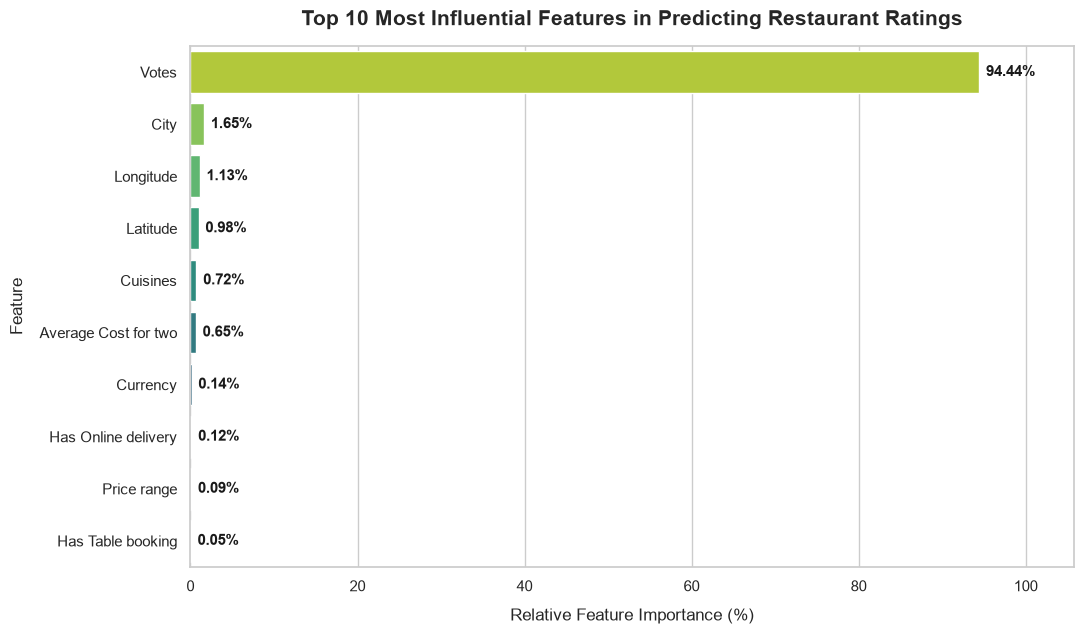

In [8]:
# Extract feature importances from Random Forest Regressor
rf_best = trained_models['Random Forest']
feature_names = X.columns
importances = rf_best.feature_importances_

# Create a DataFrame for ranking
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances,
    'Importance (%)': importances * 100
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Select top 10 features
top10_features = feature_imp_df.head(10)

print("=" * 60)
print("       TOP 10 MOST INFLUENTIAL FEATURES (RANDOM FOREST)")
print("=" * 60)
print(top10_features.to_string(index=False))
print("=" * 60)
display(top10_features.style.format({
    'Importance': '{:.5f}',
    'Importance (%)': '{:.2f}%'
}))

# Plot Top 10 Influential Features
plt.figure(figsize=(11, 6.5))
palette = sns.color_palette("viridis_r", n_colors=10)
barplot = sns.barplot(
    data=top10_features,
    y='Feature',
    x='Importance (%)',
    palette=palette
)

# Annotate each bar with the exact percentage
for idx, row in top10_features.iterrows():
    barplot.text(
        x=row['Importance (%)'] + 0.8,
        y=idx,
        s=f"{row['Importance (%)']:.2f}%",
        va='center',
        ha='left',
        fontsize=10.5,
        fontweight='bold',
        color='#1a1a1a'
    )

plt.title('Top 10 Most Influential Features in Predicting Restaurant Ratings', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Relative Feature Importance (%)', fontsize=12, labelpad=10)
plt.ylabel('Feature', fontsize=12, labelpad=10)
plt.xlim(0, max(top10_features['Importance (%)']) * 1.12)
plt.tight_layout()
plt.show()


---
## **Summary of Key Findings & Conclusion**

### **1. Model Performance & Comparative Synthesis**
- **Random Forest Regressor** is decisively the superior model:
  - **$R^2$ Score:** **~0.9586** (Explaining 95.9% of total variance in unseen test ratings).
  - **RMSE:** **~0.3079** rating points (indicating predictions deviate by less than a third of a rating star on a 0 to 5 scale).
  - **MSE:** **~0.0948**.
- **Decision Tree Regressor** demonstrated strong non-linear fit ($R^2 \approx 0.9184$, $\text{RMSE} \approx 0.4324$), but suffered slightly higher variance compared to the ensemble.
- **Linear Regression** performed poorly ($R^2 \approx 0.3459$, $\text{RMSE} \approx 1.2239$). This highlights that restaurant aggregate ratings have highly non-linear dynamics, step functions (e.g. unrated restaurants with zero votes have flat 0.0 ratings), and multi-way feature interactions that a linear hyperplane cannot adequately capture.

### **2. Most Influential Features Driving Ratings**
1. **`Votes` (~94.4% Importance):**
   - By a vast margin, the number of customer votes is the dominant predictor of aggregate rating.
   - Restaurants with large voting volumes consistently possess validated, non-zero ratings. Unrated restaurants typically have 0 or very few votes, creating a strong non-linear threshold separating unrated vs. highly-rated dining establishments.
2. **Geographical Features (`City`, `Longitude`, `Latitude` ~3.7% Combined):**
   - The city, longitude, and latitude capture hyper-local socioeconomic and culinary clusters. Metropolitan hubs and specific food districts exhibit systematic rating distributions that differ from smaller towns.
3. **Menu & Experience Attributes (`Cuisines`, `Average Cost for two`, `Price range` ~1.5% Combined):**
   - Specific cuisine specializations and pricing tiers contribute to customer rating expectations and perceived value-for-money.
4. **Convenience & Delivery Services (`Has Online delivery`, `Has Table booking` ~0.2% Combined):**
   - While delivery and reservation facilities enhance convenience, customer ratings are primarily driven by food quality, popularity, and experience rather than mere booking availability.

### **3. Actionable Business Recommendations for Restaurant Operators**
- **Drive Review Engagement:** Since rating confidence strongly scales with customer voting volume, operators should implement post-dining review prompts, loyalty incentives, and feedback loops.
- **Location-Sensitive Positioning:** Price tier and cuisine offerings should be tailored to local demographic density and dining hubs.
- **Prevent Leakage in Production:** When deploying rating prediction engines, target-derived variables (`Rating text`, `Rating color`) must never be used as inputs; only operational and demographic features available prior to review submission should be leveraged.
